# Atributos de AwA2 agrupados por origen (animal vs. fondo) — `entropy_l001` (2026-11-02)

**Pregunta.** En el modelo con penalización de entropía λ = 0.01 (`vit-15-entropy_l001-s0-AwA2`), ¿las cabezas codifican distinto los atributos que vienen **del animal** (color, textura, forma, partes del cuerpo) que los que vienen **del fondo / hábitat** (`ocean`, `desert`, `forest`...)? ¿Hay un patrón por cabeza?

**Material.** Reutiliza los resultados de `notebooks/25092026_awa2_probing/probing_awa2_entropy.ipynb` (R² del probe lineal por cabeza × atributo, nulo por permutación de clases y selectividad) y agrega tres cosas que ese notebook no tiene:

1. Comparación **grupo a grupo contra el nulo** (¿"hábitat > animal" es más de lo esperable solo por cómo están distribuidos los atributos?).
2. Un **control de confusión**: en AwA2 los atributos son constantes por clase, así que `ocean` se puede predecir reconociendo una foca. Se residualiza cada grupo sobre el otro (a nivel de clase) y se vuelve a probar.
3. Un **proxy espacial**: dónde mira cada cabeza (centro vs. bordes del 8×8 de parches).

> **Advertencia de lectura.** AwA2 no trae máscaras ni cajas del animal. "Fondo" aquí es el grupo de atributos de hábitat, no una región de la imagen.

## 0. Configuración

In [1]:
# ======================================================================
MODEL_KEY = "entropy_l001"     # λ = 0.01  ->  vit-15-entropy_l001-s0-AwA2
REFERENCE = "unconstrained"    # modelo de comparación (sin penalizar)
MODELS = {
    "unconstrained": "vit-15-AwA2",
    "constrained": "vit-15-constrained-AwA2",
    "constrained_rank": "vit-15-constrained_rank-AwA2",
    "entropy_l01": "vit-15-entropy_l01-s0-AwA2",
    "entropy_l001": "vit-15-entropy_l001-s0-AwA2",
    "entropy_l0001": "vit-15-entropy_l0001-s0-AwA2",
}
BLOCK_IDX = 4        # 1-indexed, como en probing_awa2.ipynb
N_PERM = 100         # permutaciones de clase para los controles nuevos (mismo valor que el notebook de probing)
N_FOLDS = 5
ALPHA = 0.05
SEED = 0

# Agrupación por origen visual (la misma taxonomía de comentarios de VISUAL_ATTRS en probing_awa2.ipynb)
GROUPS = {
    "color":   ["black", "white", "blue", "brown", "gray", "orange", "red", "yellow"],
    "textura": ["patches", "spots", "stripes", "furry", "hairless", "toughskin"],
    "forma":   ["big", "small", "bulbous", "lean"],
    "partes":  ["flippers", "hands", "hooves", "pads", "paws", "longleg", "longneck", "tail",
                "chewteeth", "meatteeth", "buckteeth", "strainteeth", "horns", "claws", "tusks"],
    "hábitat": ["arctic", "coastal", "desert", "bush", "plains", "forest", "fields", "jungle",
                "mountains", "ocean", "ground", "water", "tree", "cave"],
}
ANIMAL = [a for g in ("color", "textura", "forma", "partes") for a in GROUPS[g]]   # 33 atributos del animal
FONDO = GROUPS["hábitat"]                                                             # 14 atributos del fondo
MACRO = {"animal (cuerpo)": ANIMAL, "fondo (hábitat)": FONDO}
# ======================================================================

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.cluster.hierarchy import leaves_list, linkage
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

project_root = Path.cwd().resolve().parents[1]
sys.path.append(str(project_root))

from modules.datasets import AwA2Dataset
from modules.figures import save_fig
from modules.model import ViTForClassfication

torch.manual_seed(SEED)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

EXPERIMENTS_DIR = project_root / "experimentation" / "experiments"
PROBING_DIR = EXPERIMENTS_DIR / "25092026_awa2_probing_entropy"        # resultados del notebook de probing
OUTPUT_DIR = EXPERIMENTS_DIR / "02112026_attribute_groups_entropy"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RUN_TAG = f"block{BLOCK_IDX}_cls_visual"
print(f"modelo: {MODEL_KEY} -> {MODELS[MODEL_KEY]} | referencia: {REFERENCE} | device: {device}")
print(f"salidas: {OUTPUT_DIR.relative_to(project_root)}")

/home/claude/work/ennv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/11/02 15:50:44 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /home/claude/work/ennv/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


modelo: entropy_l001 -> vit-15-entropy_l001-s0-AwA2 | referencia: unconstrained | device: cpu
salidas: experimentation/experiments/02112026_attribute_groups_entropy


## 1. Datos y resultados de probing ya calculados

Se leen del notebook de probing (R² fuera de muestra, 5 folds por imagen, Ridge por atributo). Los nulos son `(100 permutaciones, 4 cabezas, 47 atributos)`: se permutan las filas de la matriz clase × atributo, así que conservan la distribución de cada atributo y la estructura por clase, pero rompen la relación con lo que la cabeza ve.

In [2]:
dataset = AwA2Dataset(image_size=32, root=str(project_root / "data" / "awa2"))
_, testloader, classes = dataset.get_loaders(batch_size=256)
labels = dataset.testset.labels.numpy()
n_cls = len(classes)

r2 = {k: pd.read_csv(PROBING_DIR / f"r2_{k}_{RUN_TAG}.csv", index_col=0) for k in MODELS}
sel = {k: pd.read_csv(PROBING_DIR / f"selectivity_{k}_{RUN_TAG}.csv", index_col=0) for k in MODELS}
null = {k: np.load(PROBING_DIR / f"null_r2_permclass_{k}_{RUN_TAG}.npy") for k in MODELS}   # (P, H, A)

attr_names = list(r2[MODEL_KEY].columns)
head_labels = list(r2[MODEL_KEY].index)
n_heads, n_attr = len(head_labels), len(attr_names)
A = {a: i for i, a in enumerate(attr_names)}
assert set(attr_names) == set(ANIMAL) | set(FONDO), "la agrupación no cubre exactamente los atributos del probing"
assert all(null[k].shape == (N_PERM, n_heads, n_attr) for k in MODELS)

# Matriz clase × atributo (50 × 47), en el orden de columnas del probing
ds_names = list(dataset.attribute_names)
cols = [ds_names.index(a) for a in attr_names]
Y_img = dataset.attributes_continuous[labels].numpy()[:, cols]            # (N, 47) por imagen
class_attr = np.zeros((n_cls, n_attr)); class_attr[labels] = Y_img        # (50, 47)
group_of = {a: g for g, attrs in GROUPS.items() for a in attrs}
print(f"{n_attr} atributos ({len(ANIMAL)} del animal, {len(FONDO)} del fondo), {n_cls} clases, {len(labels)} imágenes de test")
print({g: len(v) for g, v in GROUPS.items()})

47 atributos (33 del animal, 14 del fondo), 50 clases, 7468 imágenes de test
{'color': 8, 'textura': 6, 'forma': 4, 'partes': 15, 'hábitat': 14}


## 2. R² y selectividad por cabeza × grupo

**Selectividad** = R² real − media del R² con clases permutadas (control de capacidad del probe, Hewitt & Liang 2019). La banda del nulo es el percentil 2.5–97.5 de la media del grupo bajo permutación. El `p` es la fracción de permutaciones con media de grupo ≥ la observada (con corrección +1).

In [3]:
def group_table(key):
    rows = []
    for h_i, h in enumerate(head_labels):
        for g, attrs in {**GROUPS, **MACRO}.items():
            ix = [A[a] for a in attrs]
            obs = r2[key].iloc[h_i, ix].mean()
            nul = null[key][:, h_i, ix].mean(1)
            rows.append({"modelo": key, "cabeza": h, "grupo": g, "n_attr": len(ix), "R²": obs,
                         "R² nulo": nul.mean(), "nulo 2.5%": np.percentile(nul, 2.5), "nulo 97.5%": np.percentile(nul, 97.5),
                         "selectividad": obs - nul.mean(), "p": (1 + (nul >= obs).sum()) / (len(nul) + 1)})
    return pd.DataFrame(rows)

gt = group_table(MODEL_KEY)
gt.to_csv(OUTPUT_DIR / f"group_stats_{MODEL_KEY}.csv", index=False)
order = list(GROUPS) + list(MACRO)
print(f"=== {MODEL_KEY}: R² medio por grupo y cabeza ===")
print(gt.pivot(index="grupo", columns="cabeza", values="R²").loc[order].round(3))
print(f"\n=== {MODEL_KEY}: selectividad (R² − nulo) ===")
print(gt.pivot(index="grupo", columns="cabeza", values="selectividad").loc[order].round(3))
print(f"\n=== p-valor de la media de grupo frente al nulo (azar ≈ {ALPHA}) ===")
print(gt.pivot(index="grupo", columns="cabeza", values="p").loc[order].round(3))

=== entropy_l001: R² medio por grupo y cabeza ===
cabeza           head 1  head 2  head 3  head 4
grupo                                          
color             0.048   0.046   0.054   0.051
textura           0.032   0.050   0.067   0.065
forma             0.040   0.047   0.051   0.072
partes            0.049   0.052   0.069   0.071
hábitat           0.063   0.058   0.090   0.084
animal (cuerpo)   0.045   0.050   0.063   0.065
fondo (hábitat)   0.063   0.058   0.090   0.084

=== entropy_l001: selectividad (R² − nulo) ===
cabeza           head 1  head 2  head 3  head 4
grupo                                          
color             0.027   0.026   0.030   0.030
textura           0.011   0.028   0.043   0.043
forma             0.019   0.026   0.027   0.051
partes            0.029   0.031   0.045   0.049
hábitat           0.042   0.037   0.065   0.062
animal (cuerpo)   0.024   0.029   0.039   0.044
fondo (hábitat)   0.042   0.037   0.065   0.062

=== p-valor de la media de grupo fren

guardado: experimentation/experiments/02112026_attribute_groups_entropy/group_head_heatmap_entropy_l001.png


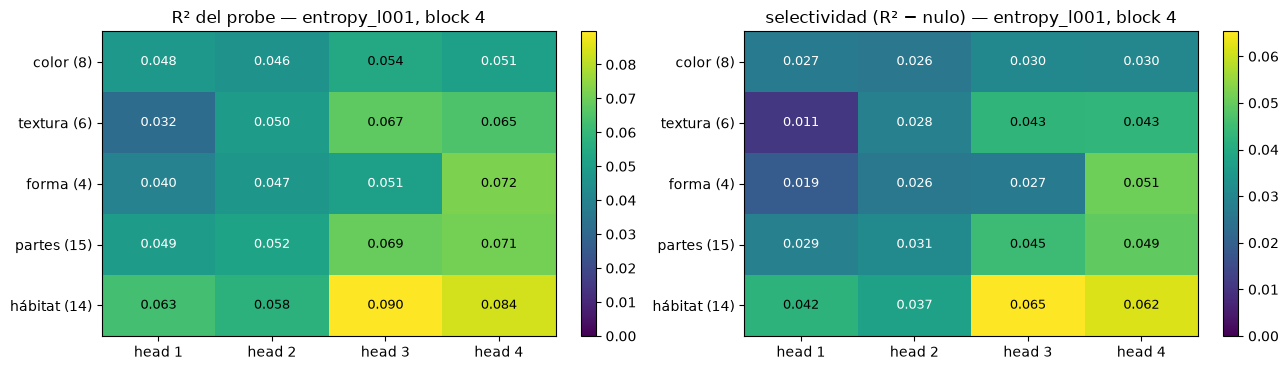

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (col, title) in zip(axes, [("R²", "R² del probe"), ("selectividad", "selectividad (R² − nulo)")]):
    M_ = gt.pivot(index="grupo", columns="cabeza", values=col).loc[list(GROUPS)]
    im = ax.imshow(M_.values, cmap="viridis", vmin=0, aspect="auto")
    ax.set_xticks(range(n_heads)); ax.set_xticklabels(head_labels)
    ax.set_yticks(range(len(M_))); ax.set_yticklabels([f"{g} ({len(GROUPS[g])})" for g in M_.index])
    for i in range(M_.shape[0]):
        for j in range(M_.shape[1]):
            ax.text(j, i, f"{M_.values[i, j]:.3f}", ha="center", va="center", fontsize=9,
                    color="white" if M_.values[i, j] < 0.6 * M_.values.max() else "black")
    ax.set_title(f"{title} — {MODEL_KEY}, block {BLOCK_IDX}")
    fig.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
save_fig(fig, "group_head_heatmap", OUTPUT_DIR, tag=MODEL_KEY, project_root=project_root)
plt.show()

### ¿"Hábitat > animal" es más de lo esperable por azar?

Los atributos de hábitat tienen más R² que los del animal en casi todos los modelos, y eso puede deberse a **cómo están repartidos los atributos entre las 50 clases** y no a lo que hace la cabeza. El nulo lo controla: la diferencia hábitat − animal bajo permutación de clases da el valor esperable sin información de la imagen. El **exceso** es la diferencia observada menos la del nulo.

In [5]:
def delta_table(key):
    ia, ifo = [A[a] for a in ANIMAL], [A[a] for a in FONDO]
    rows = []
    for h_i, h in enumerate(head_labels):
        d_obs = r2[key].iloc[h_i, ifo].mean() - r2[key].iloc[h_i, ia].mean()
        d_nul = null[key][:, h_i, ifo].mean(1) - null[key][:, h_i, ia].mean(1)
        exceso = d_obs - d_nul.mean()
        rows.append({"modelo": key, "cabeza": h, "R² animal": r2[key].iloc[h_i, ia].mean(), "R² fondo": r2[key].iloc[h_i, ifo].mean(),
                     "Δ obs (fondo − animal)": d_obs, "Δ esperado (nulo)": d_nul.mean(), "exceso": exceso,
                     "p (exceso > 0)": (1 + (d_nul >= d_obs).sum()) / (len(d_nul) + 1)})
    return pd.DataFrame(rows)

delta = pd.concat([delta_table(k) for k in MODELS], ignore_index=True)
delta.to_csv(OUTPUT_DIR / "delta_fondo_vs_animal_all_models.csv", index=False)
print(delta[delta["modelo"] == MODEL_KEY].set_index("cabeza").drop(columns="modelo").round(3))
print("\nExceso medio sobre las 4 cabezas, por modelo (>0: el fondo se decodifica mejor que lo esperable):")
print(delta.groupby("modelo")[["R² animal", "R² fondo", "Δ obs (fondo − animal)", "Δ esperado (nulo)", "exceso"]].mean().loc[list(MODELS)].round(3))

        R² animal  R² fondo  Δ obs (fondo − animal)  Δ esperado (nulo)  \
cabeza                                                                   
head 1      0.045     0.063                   0.018             -0.000   
head 2      0.050     0.058                   0.008             -0.001   
head 3      0.063     0.090                   0.027              0.000   
head 4      0.065     0.084                   0.019              0.001   

        exceso  p (exceso > 0)  
cabeza                          
head 1   0.019            0.01  
head 2   0.009            0.05  
head 3   0.027            0.01  
head 4   0.018            0.01  

Exceso medio sobre las 4 cabezas, por modelo (>0: el fondo se decodifica mejor que lo esperable):
                  R² animal  R² fondo  Δ obs (fondo − animal)  \
modelo                                                          
unconstrained         0.066     0.100                   0.034   
constrained           0.041     0.052                   0.011  

## 3. Atributo por atributo

Selectividad de cada atributo en cada cabeza, agrupada por origen. Las líneas blancas separan los grupos.

guardado: experimentation/experiments/02112026_attribute_groups_entropy/attribute_selectivity_by_group_entropy_l001.png


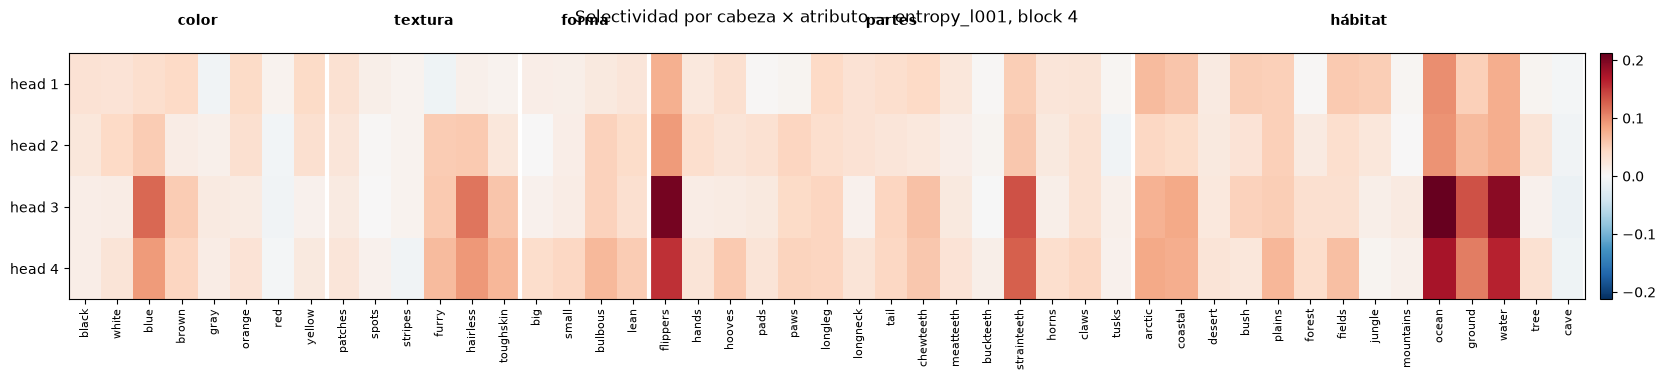

Cabeza ganadora por atributo (cuántos atributos de cada grupo gana cada cabeza) — entropy_l001
         n_attr  head 1  head 2  head 3  head 4  con p<0.05 en su mejor cabeza
grupo                                                                         
color         8       4       1       3       0                              6
textura       6       1       0       2       3                              4
forma         4       0       0       0       4                              4
partes       15       0       3       5       7                             12
hábitat      14       3       0       5       6                             12

Atributos ganados por cada cabeza (R² de la cabeza ganadora):
  head 1 ( 0 con R²>0.1): 
  head 2 ( 0 con R²>0.1): 
  head 3 ( 8 con R²>0.1): ocean[háb] 0.24, flippers[par] 0.23, water[háb] 0.22, ground[háb] 0.16, strainteeth[par] 0.16, blue[col] 0.14, hairless[tex] 0.14, coastal[háb] 0.10
  head 4 ( 0 con R²>0.1): 


In [6]:
S = sel[MODEL_KEY][attr_names]
ordered = [a for g in GROUPS for a in GROUPS[g]]
fig, ax = plt.subplots(figsize=(20, 3.2))
vmax = S.values.max()
im = ax.imshow(S[ordered].values, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_yticks(range(n_heads)); ax.set_yticklabels(head_labels)
ax.set_xticks(range(len(ordered))); ax.set_xticklabels(ordered, rotation=90, fontsize=8)
pos = 0
for g, attrs in GROUPS.items():
    pos += len(attrs)
    ax.axvline(pos - 0.5, color="w", lw=3)
    ax.text(pos - len(attrs) / 2 - 0.5, -0.9, g, ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_title(f"Selectividad por cabeza × atributo — {MODEL_KEY}, block {BLOCK_IDX}", pad=22)
fig.colorbar(im, ax=ax, fraction=0.012, pad=0.01)
save_fig(fig, "attribute_selectivity_by_group", OUTPUT_DIR, tag=MODEL_KEY, project_root=project_root)
plt.show()

# Cabeza ganadora (mayor R²) por atributo, contada por grupo, y atributos con p<ALPHA en su mejor cabeza
pval = (1 + (null[MODEL_KEY] >= r2[MODEL_KEY].values[None]).sum(0)) / (N_PERM + 1)      # (H, A)
best = r2[MODEL_KEY].values.argmax(0)
rows = []
for g, attrs in GROUPS.items():
    ix = [A[a] for a in attrs]
    row = {"grupo": g, "n_attr": len(ix)}
    row.update({head_labels[h]: int((best[ix] == h).sum()) for h in range(n_heads)})
    row["con p<%.2f en su mejor cabeza" % ALPHA] = int(sum(pval[best[i], i] < ALPHA for i in ix))
    rows.append(row)
wins = pd.DataFrame(rows).set_index("grupo")
wins.to_csv(OUTPUT_DIR / f"best_head_counts_{MODEL_KEY}.csv")
print(f"Cabeza ganadora por atributo (cuántos atributos de cada grupo gana cada cabeza) — {MODEL_KEY}")
print(wins)
print("\nAtributos ganados por cada cabeza (R² de la cabeza ganadora):")
for h in range(n_heads):
    won = [a for a in np.argsort(-r2[MODEL_KEY].values[h]) if best[a] == h and r2[MODEL_KEY].values[h, a] > 0.1]
    print(f"  {head_labels[h]} ({len(won):2d} con R²>0.1): " + ", ".join(f"{attr_names[a]}[{group_of[attr_names[a]][:3]}] {r2[MODEL_KEY].values[h, a]:.2f}" for a in won))

## 4. ¿Los atributos del "fondo" son realmente del fondo? Estructura entre atributos a nivel de clase

Como cada atributo es constante por clase, dos atributos que aparecen en las mismas especies son indistinguibles para el probe. Si `ocean`, `water`, `flippers` y `blue` pertenecen a las mismas clases (foca, ballena, delfín...), una cabeza que "sabe" `ocean` puede estar reconociendo al animal. Aquí se mide esa dependencia.

guardado: experimentation/experiments/02112026_attribute_groups_entropy/attribute_class_correlation_all_models.png


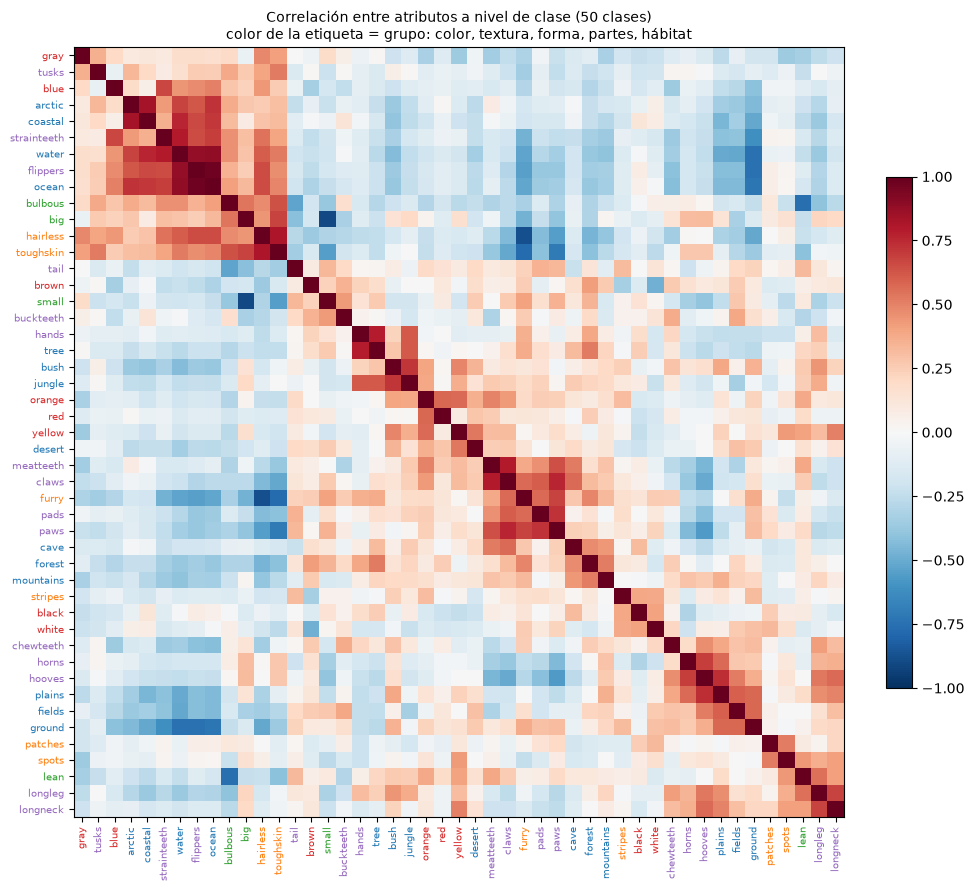

Atributos del hábitat y sus 4 atributos del ANIMAL más correlacionados a nivel de clase:
     arctic: flippers +0.62, strainteeth +0.43, bulbous +0.37, tusks +0.33
    coastal: flippers +0.66, longleg -0.37, strainteeth +0.36, bulbous +0.31
     desert: yellow +0.53, orange +0.36, red +0.28, flippers -0.26
       bush: yellow +0.49, longleg +0.44, orange +0.40, flippers -0.36
     plains: hooves +0.74, horns +0.57, longneck +0.50, longleg +0.47
     forest: furry +0.49, hairless -0.47, brown +0.42, toughskin -0.41
     fields: hooves +0.51, flippers -0.42, strainteeth -0.40, buckteeth +0.38
     jungle: hands +0.61, orange +0.39, longleg +0.37, yellow +0.36
  mountains: hairless -0.39, strainteeth -0.36, flippers -0.33, furry +0.32
      ocean: flippers +0.97, strainteeth +0.69, hairless +0.65, furry -0.52
     ground: flippers -0.74, strainteeth -0.61, hairless -0.51, blue -0.41
      water: flippers +0.88, strainteeth +0.79, hairless +0.61, furry -0.53
       tree: hands +0.79, furry

In [7]:
corr = pd.DataFrame(np.corrcoef(class_attr.T), index=attr_names, columns=attr_names).fillna(0)
Z = linkage(1 - corr.values[np.triu_indices(n_attr, 1)], method="average")
leaf = leaves_list(Z)
names_l = [attr_names[i] for i in leaf]
fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(corr.loc[names_l, names_l].values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(n_attr)); ax.set_xticklabels(names_l, rotation=90, fontsize=7)
ax.set_yticks(range(n_attr)); ax.set_yticklabels(names_l, fontsize=7)
palette = {"color": "tab:red", "textura": "tab:orange", "forma": "tab:green", "partes": "tab:purple", "hábitat": "tab:blue"}
for lab in ax.get_xticklabels() + ax.get_yticklabels():
    lab.set_color(palette[group_of[lab.get_text()]])
ax.set_title("Correlación entre atributos a nivel de clase (50 clases)\ncolor de la etiqueta = grupo: " +
             ", ".join(f"{g}" for g in palette), fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.03)
save_fig(fig, "attribute_class_correlation", OUTPUT_DIR, tag="all_models", project_root=project_root)
plt.show()

print("Atributos del hábitat y sus 4 atributos del ANIMAL más correlacionados a nivel de clase:")
for a in FONDO:
    c = corr.loc[a, ANIMAL].sort_values(key=np.abs, ascending=False).head(4)
    print(f"  {a:>9}: " + ", ".join(f"{k} {v:+.2f}" for k, v in c.items()))

## 5. Control de confusión: residualizar un grupo sobre el otro

Para cada atributo del **hábitat** se ajusta una regresión (Ridge, validación **dejando una clase fuera**) que lo predice desde los 33 atributos del **animal**. La parte que el animal *no* explica es el **residuo de hábitat**: lo que queda de "fondo" una vez descontada la identidad del animal. Se vuelve a probar ese residuo desde la salida de cada cabeza, con los mismos folds. Se hace también lo simétrico (animal | hábitat).

Si el R² del residuo cae a ≈ el nulo, la cabeza no lee el fondo más allá de reconocer al animal. El nulo permuta las filas de clase del residuo, igual que en el probing original.

In [8]:
def loco_residual(target_ix, predictor_ix):
    """Residuo fuera de muestra (dejando una clase fuera) de los atributos `target_ix` dado `predictor_ix`, a nivel de clase."""
    X, Y = class_attr[:, predictor_ix], class_attr[:, target_ix]
    P = np.zeros_like(Y)
    for c in range(n_cls):
        tr = np.arange(n_cls) != c
        m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 12)))
        P[c] = m.fit(X[tr], Y[tr]).predict(X[[c]])
    return Y - P, r2_score(Y, P, multioutput="raw_values")

ia, ifo = [A[a] for a in ANIMAL], [A[a] for a in FONDO]
resid_fondo, expl_fondo = loco_residual(ifo, ia)        # hábitat | animal
resid_animal, expl_animal = loco_residual(ia, ifo)      # animal | hábitat
print(f"Varianza (entre clases) del HÁBITAT explicada por los atributos del animal (R² dejando una clase fuera):\n"
      f"   media {expl_fondo.mean():.2f}  |  " + ", ".join(f"{a} {v:.2f}" for a, v in zip(FONDO, expl_fondo)))
print(f"Varianza del ANIMAL explicada por los atributos del hábitat:\n"
      f"   media {expl_animal.mean():.2f}  |  mediana {np.median(expl_animal):.2f}")

Varianza (entre clases) del HÁBITAT explicada por los atributos del animal (R² dejando una clase fuera):
   media 0.23  |  arctic 0.04, coastal 0.02, desert 0.08, bush -0.04, plains 0.49, forest -0.01, fields 0.38, jungle 0.26, mountains -0.27, ocean 0.68, ground 0.49, water 0.61, tree 0.26, cave 0.16
Varianza del ANIMAL explicada por los atributos del hábitat:
   media 0.10  |  mediana 0.08


In [9]:
@torch.no_grad()
def extract(model):
    """Salida de cada cabeza (token CLS) y atención CLS->parches del bloque BLOCK_IDX, sobre todo el test."""
    cap, b0 = {}, BLOCK_IDX - 1
    hooks = [h.register_forward_hook(lambda _m, _i, out, k=k: cap.__setitem__(k, out[0]))
             for k, h in enumerate(model.encoder.blocks[b0].attention.heads)]
    feats, atts = [], []
    try:
        for images, _, _ in testloader:
            _, att = model(images.to(device), output_attentions=True)
            feats.append(torch.stack([cap[k] for k in range(n_heads)], dim=1)[:, :, 0].cpu())
            atts.append(att[b0][:, :, 0, 1:].cpu())
    finally:
        for h in hooks:
            h.remove()
    return torch.cat(feats).numpy(), torch.cat(atts).numpy()


def load_model(name):
    exp_dir = EXPERIMENTS_DIR / name
    config = json.loads((exp_dir / "config.json").read_text())
    model = ViTForClassfication(config)
    model.load_state_dict(torch.load(exp_dir / "model_final.pt", map_location="cpu"))
    return model.to(device).eval()


feats, atts = {}, {}
for key in (MODEL_KEY, REFERENCE):
    feats[key], atts[key] = extract(load_model(MODELS[key]))
    print(f"{key}: feats {feats[key].shape}, atención {atts[key].shape}")

entropy_l001: feats (7468, 4, 12), atención (7468, 4, 64)


unconstrained: feats (7468, 4, 12), atención (7468, 4, 64)


In [10]:
folds_image = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(labels, labels))


def probe_r2(X, Y, folds):
    """R² out-of-fold por atributo (Ridge multisalida, alpha por atributo dentro de cada fold). Igual que probing_awa2.ipynb."""
    pred = np.zeros_like(Y)
    for tr, te in folds:
        probe = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13), alpha_per_target=True))
        pred[te] = probe.fit(X[tr], Y[tr]).predict(X[te])
    return r2_score(Y, pred, multioutput="raw_values")


rng = np.random.default_rng(SEED)
perms = [rng.permutation(n_cls) for _ in range(N_PERM)]
TARGETS = {   # nombre -> (matriz clase×atributo del objetivo, columnas de class_attr que corresponde)
    "fondo | animal": (resid_fondo, ifo, "hábitat residualizado sobre el animal"),
    "animal | fondo": (resid_animal, ia, "animal residualizado sobre el hábitat"),
}
rows, per_attr = [], []
for key in (MODEL_KEY, REFERENCE):
    for tname, (resid_c, raw_ix, desc) in TARGETS.items():
        Y_res = resid_c[labels]                                   # (N, k) residuo por imagen
        Y_raw = class_attr[:, raw_ix][labels]                     # (N, k) valor original (para comparar en el mismo marco)
        for h in range(n_heads):
            raw = probe_r2(feats[key][:, h], Y_raw, folds_image)
            res = probe_r2(feats[key][:, h], Y_res, folds_image)
            nul = np.array([probe_r2(feats[key][:, h], resid_c[p][labels], folds_image) for p in perms])   # (P, k)
            nul_m = nul.mean(1)
            rows.append({"modelo": key, "objetivo": tname, "cabeza": head_labels[h], "R² original": raw.mean(), "R² residuo": res.mean(),
                         "R² nulo (residuo)": nul_m.mean(), "nulo 2.5%": np.percentile(nul_m, 2.5), "nulo 97.5%": np.percentile(nul_m, 97.5),
                         "selectividad residuo": res.mean() - nul_m.mean(), "p": (1 + (nul_m >= res.mean()).sum()) / (N_PERM + 1)})
            names_t = [attr_names[i] for i in raw_ix]
            per_attr += [{"modelo": key, "objetivo": tname, "cabeza": head_labels[h], "atributo": n, "R² original": r, "R² residuo": s,
                          "p": (1 + (nul[:, j] >= s).sum()) / (N_PERM + 1)} for j, (n, r, s) in enumerate(zip(names_t, raw, res))]
resid_df, per_attr_df = pd.DataFrame(rows), pd.DataFrame(per_attr)
resid_df.to_csv(OUTPUT_DIR / "residual_probing_summary.csv", index=False)
per_attr_df.to_csv(OUTPUT_DIR / "residual_probing_per_attribute.csv", index=False)
for tname in TARGETS:
    print(f"=== objetivo: {tname}  ({TARGETS[tname][2]}) ===")
    print(resid_df[resid_df["objetivo"] == tname].drop(columns="objetivo").round(3).to_string(index=False))
    print()

=== objetivo: fondo | animal  (hábitat residualizado sobre el animal) ===
       modelo cabeza  R² original  R² residuo  R² nulo (residuo)  nulo 2.5%  nulo 97.5%  selectividad residuo     p
 entropy_l001 head 1        0.063       0.032              0.021      0.012       0.030                 0.011 0.030
 entropy_l001 head 2        0.058       0.022              0.020      0.013       0.029                 0.002 0.297
 entropy_l001 head 3        0.090       0.035              0.023      0.014       0.032                 0.012 0.020
 entropy_l001 head 4        0.084       0.029              0.021      0.014       0.030                 0.008 0.050
unconstrained head 1        0.097       0.037              0.018      0.010       0.027                 0.020 0.020
unconstrained head 2        0.117       0.045              0.030      0.020       0.044                 0.015 0.020
unconstrained head 3        0.096       0.038              0.023      0.015       0.032                 0.015 0.02

guardado: experimentation/experiments/02112026_attribute_groups_entropy/residual_probing_entropy_l001.png


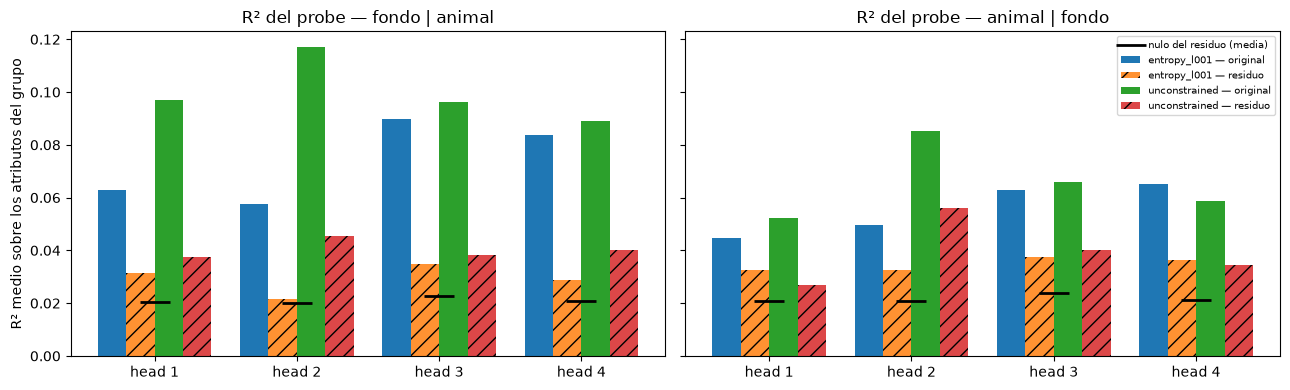

entropy_l001: R² original -> R² del residuo, mejor cabeza por atributo del fondo
      ocean: head 3  original 0.237 -> residuo 0.107  (p residuo = 0.01)
      water: head 3  original 0.217 -> residuo 0.082  (p residuo = 0.02)
    coastal: head 3  original 0.103 -> residuo 0.046  (p residuo = 0.05)
     arctic: head 4  original 0.100 -> residuo 0.043  (p residuo = 0.04)
     desert: head 4  original 0.049 -> residuo 0.011  (p residuo = 0.78)
     forest: head 4  original 0.059 -> residuo 0.018  (p residuo = 0.61)
     jungle: head 1  original 0.073 -> residuo 0.036  (p residuo = 0.10)
  mountains: head 3  original 0.046 -> residuo 0.015  (p residuo = 0.68)


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
w = 0.2
for ax, tname in zip(axes, TARGETS):
    sub = resid_df[resid_df["objetivo"] == tname]
    for i, key in enumerate((MODEL_KEY, REFERENCE)):
        s = sub[sub["modelo"] == key]
        x = np.arange(n_heads)
        ax.bar(x + (2 * i - 1.5) * w, s["R² original"], width=w, label=f"{key} — original")
        ax.bar(x + (2 * i - 0.5) * w, s["R² residuo"], width=w, label=f"{key} — residuo", hatch="//", alpha=0.85)
    nul = sub[sub["modelo"] == MODEL_KEY]["R² nulo (residuo)"].values
    ax.plot(np.arange(n_heads), nul, "k_", ms=22, mew=2, label="nulo del residuo (media)")
    ax.set_xticks(range(n_heads)); ax.set_xticklabels(head_labels)
    ax.set_title(f"R² del probe — {tname}")
axes[0].set_ylabel("R² medio sobre los atributos del grupo")
axes[1].legend(fontsize=7, loc="upper right")
plt.tight_layout()
save_fig(fig, "residual_probing", OUTPUT_DIR, tag=MODEL_KEY, project_root=project_root)
plt.show()

# Atributos puntuales del fondo en el modelo de interés
foco = ["ocean", "water", "coastal", "arctic", "desert", "forest", "jungle", "mountains"]
d = per_attr_df[(per_attr_df["modelo"] == MODEL_KEY) & (per_attr_df["objetivo"] == "fondo | animal") & (per_attr_df["atributo"].isin(foco))]
print(f"{MODEL_KEY}: R² original -> R² del residuo, mejor cabeza por atributo del fondo")
for a in foco:
    s = d[d["atributo"] == a].sort_values("R² original", ascending=False).iloc[0]
    print(f"  {a:>9}: {s['cabeza']}  original {s['R² original']:.3f} -> residuo {s['R² residuo']:.3f}  (p residuo = {s['p']:.2f})")

## 6. Proxy espacial: ¿dónde mira cada cabeza?

Atención CLS → parches del bloque 4, promediada sobre las 7468 imágenes de test (rejilla 8×8). **Centro** = los 4×4 parches centrales (con atención uniforme le tocaría 25%). Es solo un proxy: los animales de AwA2 no siempre están centrados y no hay máscara, así que *no* distingue "animal" de "fondo" con certeza.

guardado: experimentation/experiments/02112026_attribute_groups_entropy/mean_attention_maps_entropy_l001.png


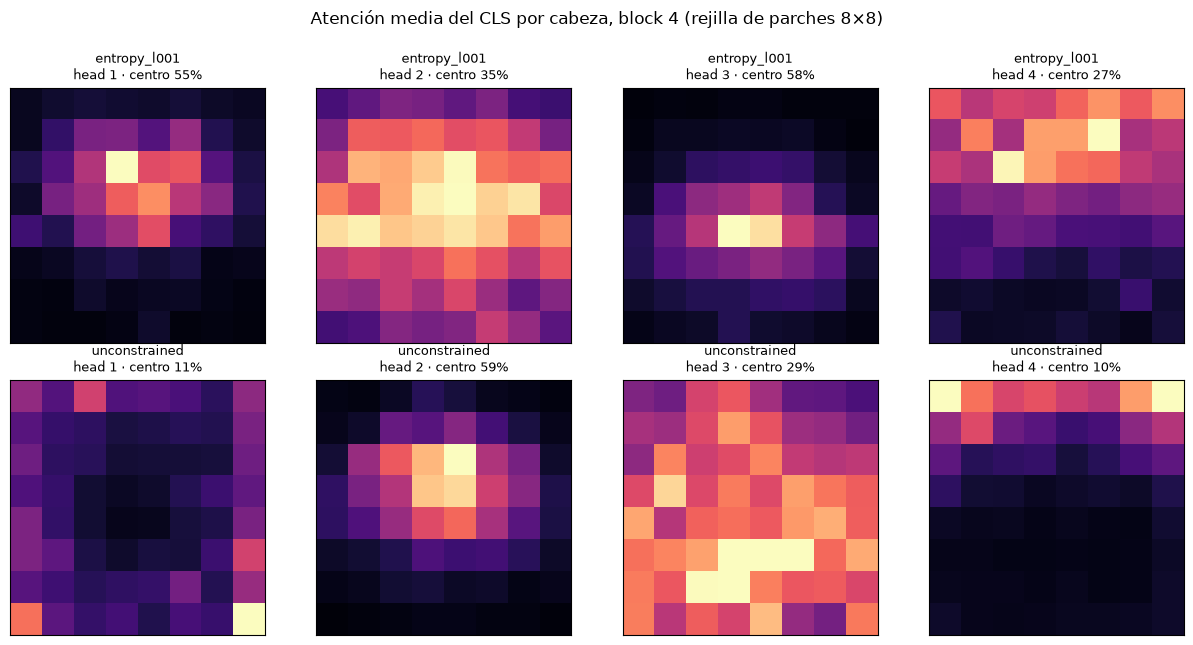

=== entropy_l001 ===
        atención en el centro (4×4)  atención en el borde  \
head 1                        0.554                 0.446   
head 2                        0.352                 0.648   
head 3                        0.580                 0.420   
head 4                        0.273                 0.727   

        peso del parche máximo  parches efectivos  
head 1                   0.391          10.348000  
head 2                   0.244          20.424999  
head 3                   0.233          18.334000  
head 4                   0.292          16.347000  
=== unconstrained ===
        atención en el centro (4×4)  atención en el borde  \
head 1                        0.108                 0.892   
head 2                        0.592                 0.408   
head 3                        0.289                 0.711   
head 4                        0.103                 0.897   

        peso del parche máximo  parches efectivos  
head 1                   0.274   

In [12]:
G = 8
spatial = {}
fig, axes = plt.subplots(2, n_heads, figsize=(3.1 * n_heads, 6.4))
for r, key in enumerate((MODEL_KEY, REFERENCE)):
    a = atts[key] / atts[key].sum(-1, keepdims=True)              # (N, H, 64) renormalizada sobre los parches
    grid = a.reshape(len(a), n_heads, G, G)
    mean_map = grid.mean(0)                                        # (H, 8, 8)
    centro = grid[:, :, 2:6, 2:6].sum((-1, -2)).mean(0)           # fracción de la atención en el centro 4×4
    top1 = a.max(-1).mean(0)
    spatial[key] = pd.DataFrame({"atención en el centro (4×4)": centro, "atención en el borde": 1 - centro,
                                 "peso del parche máximo": top1,
                                 "parches efectivos": np.exp(-(a * np.log(np.clip(a, 1e-8, None))).sum(-1)).mean(0)},
                                index=head_labels)
    for h in range(n_heads):
        ax = axes[r, h]
        im = ax.imshow(mean_map[h], cmap="magma", vmin=0)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{key}\n{head_labels[h]} · centro {centro[h]:.0%}", fontsize=9)
plt.suptitle(f"Atención media del CLS por cabeza, block {BLOCK_IDX} (rejilla de parches 8×8)", y=1.0)
plt.tight_layout()
save_fig(fig, "mean_attention_maps", OUTPUT_DIR, tag=MODEL_KEY, project_root=project_root)
plt.show()
for key in (MODEL_KEY, REFERENCE):
    print(f"=== {key} ===")
    print(spatial[key].round(3))
    spatial[key].to_csv(OUTPUT_DIR / f"spatial_proxy_{key}.csv")
print("\n(uniforme: centro 25%, parches efectivos 64)")

In [13]:
# Relación por cabeza: ¿las cabezas que miran más a los bordes se inclinan hacia el hábitat?
rows = []
for key in (MODEL_KEY, REFERENCE):
    g_ = group_table(key).pivot(index="cabeza", columns="grupo", values="selectividad")
    rows.append(pd.DataFrame({"modelo": key, "cabeza": head_labels,
                              "borde": spatial[key]["atención en el borde"].values,
                              "selectividad animal": g_.loc[head_labels, "animal (cuerpo)"].values,
                              "selectividad fondo": g_.loc[head_labels, "fondo (hábitat)"].values}))
rel = pd.concat(rows, ignore_index=True)
rel["fondo − animal"] = rel["selectividad fondo"] - rel["selectividad animal"]
rel.to_csv(OUTPUT_DIR / "edge_attention_vs_selectivity.csv", index=False)
print(rel.round(3).to_string(index=False))
r_ = np.corrcoef(rel["borde"], rel["fondo − animal"])[0, 1]
print(f"\ncorrelación (8 cabezas, 2 modelos) entre atención en el borde y (selectividad fondo − animal): r = {r_:+.2f}  "
      f"(n = {len(rel)}; sin significancia estadística, solo descriptivo)")

       modelo cabeza  borde  selectividad animal  selectividad fondo  fondo − animal
 entropy_l001 head 1  0.446                0.024               0.042           0.019
 entropy_l001 head 2  0.648                0.029               0.037           0.009
 entropy_l001 head 3  0.420                0.039               0.065           0.027
 entropy_l001 head 4  0.727                0.044               0.062           0.018
unconstrained head 1  0.892                0.033               0.078           0.045
unconstrained head 2  0.408                0.054               0.086           0.032
unconstrained head 3  0.711                0.043               0.073           0.030
unconstrained head 4  0.897                0.037               0.067           0.030

correlación (8 cabezas, 2 modelos) entre atención en el borde y (selectividad fondo − animal): r = +0.33  (n = 8; sin significancia estadística, solo descriptivo)


## 7. Conclusión (2026-11-02, `entropy_l001_s0`, 1 semilla, CPU)

1. **Hay un patrón, pero es débil y vale para todos los grupos.** Todos los grupos están por encima del nulo (p≈0.01), pero con R² de 0.03–0.09. Los atributos de **hábitat** se decodifican algo mejor que los del **animal** en las 4 cabezas (0.058–0.090 vs 0.045–0.065); el exceso sobre el nulo es 0.009–0.027 (p≤0.05). El mismo sesgo aparece en `unconstrained` (0.034) y en las demás penalizaciones, y es *menor* en `entropy_l001` (0.018): **no es un efecto de la entropía**.
2. **La señal "de fondo" es en buena parte identidad del animal.** `ocean`/`water` correlacionan 0.97/0.88 con `flippers` a nivel de clase, y el 68 % / 61 % de su varianza se explica con los atributos del animal. Al residualizar, el R² del hábitat cae a la mitad o menos (ocean 0.237→0.107, water 0.217→0.082, coastal 0.103→0.046); desert, forest y mountains quedan en el nulo. Lo que sobrevive (ocean, water, arctic, coastal) es poco y no prueba que la cabeza lea el fondo: sigue siendo a nivel de clase.
3. **Solo la cabeza 3 tiene atributos con R²>0.1** (ocean, flippers, water, ground, strainteeth, blue, hairless, coastal): es una cabeza de "marino/acuático", mezcla animal y hábitat. Las cabezas 1, 2 y 4 no superan 0.1 en ningún atributo. Por grupos, la cabeza 4 gana *forma* (4/4) y gran parte de *partes* y *textura*; la 1 gana *color* (4/8).
4. **Atención espacial:** no hay relación clara. Las cabezas con más atención en el borde no son sistemáticamente las de hábitat (r=+0.33, n=8, sin significancia).

**Límites.** Una semilla; atributos constantes por clase (no se puede separar animal de fondo sin máscaras); 50 clases; CPU en lugar de MPS. Para afirmar "esta cabeza mira el fondo" se necesita una prueba con máscaras o cajas (p. ej. CelebA con bounding box, o segmentación de AwA2), no más probing de atributos.
